# Clothes Segmentation (CVCY002) - Kaggle Notebook

Full pipeline: **dataset -> preprocessing/augmentation -> U-Net training -> evaluation -> failure analysis -> inference on personal photos -> export**.

**Before you run (Kaggle settings, right sidebar):**
1. **Accelerator:** GPU T4 x2 (both GPUs are used through `DataParallel`), or P100 / T4 x1 (single GPU, works unchanged).
2. **Internet: On** (needed for `pip install` and the pretrained ResNet34 weights).
3. **Add Input:** your uploaded ATR dataset (the extracted `train/ val/ test/` folders with `images/` and `masks/`).
4. To keep the trained model after the session ends: **Save Version -> Save & Run All (Commit)**. Files in `/kaggle/working` are only kept for committed versions.

In [1]:
!pip install -q -U segmentation-models-pytorch albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.6 MB/s eta 0:00:0000:01


In [2]:
import os, gc, ctypes, json, time, random
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from tqdm.auto import tqdm
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(42)
cv2.setNumThreads(0)                      # DataLoader workers x OpenCV threads oversubscribe Kaggle's 4 CPU cores
torch.backends.cudnn.benchmark = True     # input size is fixed -> let cuDNN pick the fastest kernels

try:                                      # hand freed heap memory back to the OS (fights worker RSS growth)
    _libc = ctypes.CDLL("libc.so.6")
    def _malloc_trim(): _libc.malloc_trim(0)
except OSError:
    def _malloc_trim(): pass


def ram_report():
    """Main-process RSS, DataLoader-worker RSS, system RAM, /dev/shm and peak GPU memory (GB)."""
    me = psutil.Process()
    main, wk = me.memory_info().rss / 1e9, 0.0
    for k in me.children(recursive=True):
        try: wk += k.memory_info().rss / 1e9
        except psutil.Error: pass
    vm = psutil.virtual_memory()
    shm = psutil.disk_usage("/dev/shm").used / 1e9 if os.path.exists("/dev/shm") else 0.0
    gpu = (max(torch.cuda.max_memory_allocated(g) for g in range(torch.cuda.device_count())) / 1e9
           if torch.cuda.is_available() else 0.0)
    return (f"RAM main {main:.1f}G + workers {wk:.1f}G | system {vm.used / 1e9:.1f}/{vm.total / 1e9:.1f}G | "
            f"shm {shm:.2f}G | gpu peak {gpu:.1f}G")

# ----------------------------- CONFIG -------------------------------------- #
CFG = dict(
    img_size=512,          # training / inference resolution (square, letterboxed)
    batch_size=16,         # PER GPU (global batch = this x number of GPUs); lower to 8 on out-of-memory
    epochs=25,
    lr=3e-4,
    weight_decay=1e-4,
    encoder="resnet34",    # baseline (~225 s/epoch on T4 x2). Stronger: "resnet50" (expect ~1.5-2x slower; lower batch_size
                           # to 12 if out of memory). Names like "efficientnet-b3" depend on your smp version.
    merge_classes=True,    # True -> 11 clothes-focused classes, False -> all 18 ATR classes
    num_workers=4,
    amp=True,              # mixed precision
    multi_gpu=False,       # DataParallel: measured 0.44x of ONE T4 on Kaggle -> keep False. Training uses DDP (section 3).
    ema=True,              # keep an exponential moving average of the weights (validated every epoch, best of raw/EMA is saved)
    ema_decay=0.999,       # ~1000-step horizon (about 2 epochs)
    tta_flip=True,         # test-time augmentation: average the prediction with the horizontally flipped one
    channels_last=True,    # faster conv kernels on tensor cores (T4/P100 + AMP)
    ram_stop_gb=24.0,      # stop cleanly (checkpoint saved) if system RAM passes this; re-run to resume
    time_budget_hours=10.0,  # stop gracefully before Kaggle's 12h session limit
    resume=True,           # continue from last.pt if it exists
)

# Set this by hand if auto-detection fails, e.g. "/kaggle/input/atr-extracted/ATRDataset_extracted"
DATA_ROOT = None


def find_root():
    for dp, dn, _ in os.walk("/kaggle/input/datasets/mahmoudosamahassan/atrdataset/ATRDataset"):
        if {"train", "val", "test"} <= set(dn):
            return Path(dp)
        if dp.count(os.sep) > 6:
            dn[:] = []
    raise FileNotFoundError("Could not find a folder with train/ val/ test/ under /kaggle/input. Set DATA_ROOT manually.")


DATA_ROOT = Path(DATA_ROOT) if DATA_ROOT else find_root()
# one output folder per encoder, so checkpoints of different architectures never get mixed up
OUT = Path("/kaggle/working/outputs" if CFG["encoder"] == "resnet34" else f"/kaggle/working/outputs_{CFG['encoder']}")
OUT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = CFG["amp"] and device.type == "cuda"
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - enable it in the sidebar")
print("data root:", DATA_ROOT)
for s in ["train", "val", "test"]:
    print(f"  {s}: {len(list((DATA_ROOT / s / 'images').glob('*.jpg')))} images")

torch 2.11.0+cu128 | device: cuda | Tesla T4
data root: /kaggle/input/datasets/mahmoudosamahassan/atrdataset/ATRDataset
  train: 16706 images
  val: 1000 images
  test: 200 images


## 1. Dataset: labels, preprocessing, augmentation

* ATR has 18 labels (0-17). By default they are merged into **11 clothes-focused classes** (hair/face/arms/legs/sunglasses -> `body`, left/right shoes -> `shoes`).
* **Horizontal flip** is done manually with a left/right label swap (shoes 9<->10, legs 12<->13, arms 14<->15), because Albumentations' flip would silently corrupt those labels.
* Images are resized with the aspect ratio preserved and zero-padded to a square.

In [3]:
ATR_NAMES = ["background", "hat", "hair", "sunglasses", "upper-clothes", "skirt", "pants", "dress", "belt",
             "left-shoe", "right-shoe", "face", "left-leg", "right-leg", "left-arm", "right-arm", "bag", "scarf"]
CLOTHES_NAMES = ["background", "body", "hat", "upper-clothes", "skirt", "pants", "dress", "belt", "shoes", "bag", "scarf"]
_CLOTHES_MAP = {0: 0, 1: 2, 2: 1, 3: 1, 4: 3, 5: 4, 6: 5, 7: 6, 8: 7, 9: 8, 10: 8,
                11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 16: 9, 17: 10}
CLOTHES_LUT = np.array([_CLOTHES_MAP[i] for i in range(18)], dtype=np.uint8)
FULL_LUT = np.arange(18, dtype=np.uint8)

FLIP_LUT = np.arange(18, dtype=np.uint8)           # swap left/right labels after a horizontal flip
for a, b in [(9, 10), (12, 13), (14, 15)]:
    FLIP_LUT[a], FLIP_LUT[b] = b, a

NON_CLOTHES = {"background", "body", "hair", "face", "sunglasses", "left-leg", "right-leg", "left-arm", "right-arm"}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

CLASS_NAMES = CLOTHES_NAMES if CFG["merge_classes"] else ATR_NAMES
NUM_CLASSES = len(CLASS_NAMES)
CLOTHES_IDS = [i for i, n in enumerate(CLASS_NAMES) if n not in NON_CLOTHES]
SIZE = CFG["img_size"]


def get_train_transform(size):
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.Affine(scale=(0.75, 1.25), translate_percent=(-0.1, 0.1), rotate=(-15, 15),
                 border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0, p=0.7),
        A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03, p=0.6),
        A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.GaussNoise()], p=0.2),
        ToTensorV2(),   # stays uint8: normalisation happens on the GPU (4x less data through workers / shared memory)
    ])


def get_eval_transform(size):
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])


class ATRDataset(Dataset):
    def __init__(self, root, split, transform=None, merge_classes=True, hflip_p=0.0):
        root = Path(root)
        self.images = sorted((root / split / "images").glob("*.jpg"))
        self.mask_dir = root / split / "masks"
        assert self.images, f"No images in {root / split / 'images'}"
        self.transform, self.hflip_p = transform, hflip_p
        self.lut = CLOTHES_LUT if merge_classes else FULL_LUT
        self._calls = 0

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        self._calls += 1
        if self._calls % 300 == 0:
            _malloc_trim()
        p = self.images[i]
        img = np.array(Image.open(p).convert("RGB"))
        mask = np.array(Image.open(self.mask_dir / f"{p.stem}.png"))
        if mask.ndim == 3:
            mask = mask[..., 0]
        mask = mask.astype(np.uint8)
        if self.hflip_p and random.random() < self.hflip_p:
            img = np.ascontiguousarray(img[:, ::-1])
            mask = FLIP_LUT[np.ascontiguousarray(mask[:, ::-1])]
        mask = self.lut[mask]
        if self.transform:
            out = self.transform(image=img, mask=mask)
            return out["image"], out["mask"].long()
        return img, mask


merge = CFG["merge_classes"]
train_ds = ATRDataset(DATA_ROOT, "train", get_train_transform(SIZE), merge, hflip_p=0.5)
val_ds = ATRDataset(DATA_ROOT, "val", get_eval_transform(SIZE), merge)
test_ds = ATRDataset(DATA_ROOT, "test", get_eval_transform(SIZE), merge)

W = CFG["num_workers"]
N_GPU = torch.cuda.device_count() if device.type == "cuda" else 0
if not CFG["multi_gpu"]:
    N_GPU = min(N_GPU, 1)
GLOBAL_BS = CFG["batch_size"] * max(N_GPU, 1)
# persistent_workers=False: workers are recycled every epoch, so any RSS they accumulate is released
dl_kw = dict(num_workers=W, pin_memory=True, persistent_workers=False, prefetch_factor=2 if W > 0 else None)
train_dl = DataLoader(train_ds, GLOBAL_BS, shuffle=True, drop_last=True, **dl_kw)
val_dl = DataLoader(val_ds, GLOBAL_BS, shuffle=False, **dl_kw)
test_dl = DataLoader(test_ds, GLOBAL_BS, shuffle=False, **dl_kw)
print(f"GPUs: {N_GPU} | global batch {GLOBAL_BS} | {len(train_dl)} steps/epoch")
print(len(train_ds), len(val_ds), len(test_ds), "| classes:", NUM_CLASSES)

GPUs: 1 | global batch 16 | 1044 steps/epoch
16706 1000 200 | classes: 11


### Sanity checks: label ids, class balance, augmented samples
Check that the augmented masks still line up with the images (colors = classes).

raw label ids found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


class frequencies:   0%|          | 0/2000 [00:00<?, ?it/s]

,class,pixel_share_%
0,background,76.33
1,body,7.32
2,hat,0.18
3,upper-clothes,6.08
4,skirt,1.92
5,pants,2.86
6,dress,2.83
7,belt,0.10
8,shoes,1.00
9,bag,1.18


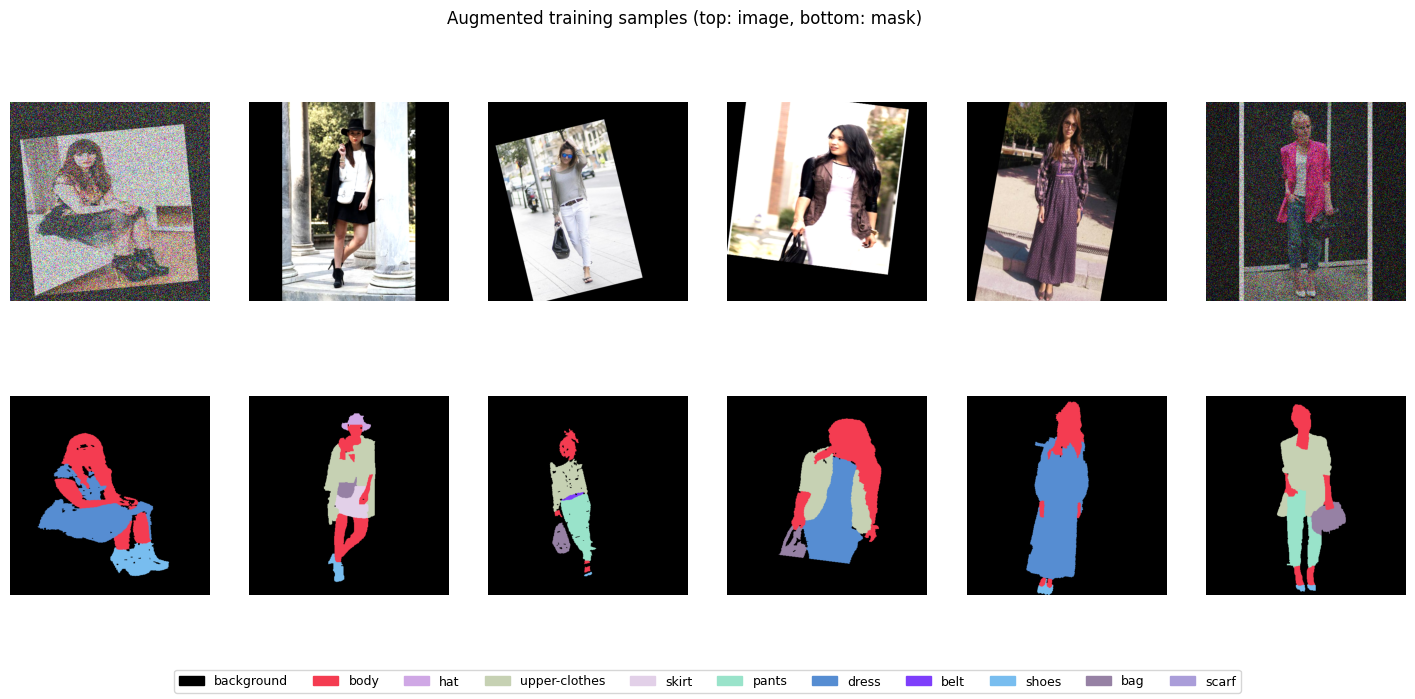

In [4]:
PALETTE = np.random.RandomState(3).randint(60, 256, (max(NUM_CLASSES, 18), 3)).astype(np.uint8)
PALETTE[0] = 0   # background = black


def denorm(x):
    x = x.permute(1, 2, 0).cpu().numpy()
    if x.dtype == np.uint8:                       # training pipeline keeps uint8 (normalised later, on the GPU)
        return x.astype(np.float32) / 255.0
    return np.clip(x * np.array(STD) + np.array(MEAN), 0, 1)


# 1) raw label ids
raw_ds = ATRDataset(DATA_ROOT, "train", None, merge_classes=False)
seen = set()
for i in range(0, len(raw_ds), max(1, len(raw_ds) // 200)):
    seen |= set(np.unique(raw_ds[i][1]).tolist())
print("raw label ids found:", sorted(seen))

# 2) class balance (merged / chosen label set)
plain_ds = ATRDataset(DATA_ROOT, "train", None, merge_classes=merge)
counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for i in tqdm(range(min(len(plain_ds), 2000)), desc="class frequencies"):
    counts += np.bincount(plain_ds[i][1].ravel(), minlength=NUM_CLASSES)
FREQ = counts / counts.sum()
freq_df = pd.DataFrame({"class": CLASS_NAMES, "pixel_share_%": (FREQ * 100).round(2)})
display(freq_df)
freq_df.to_csv(OUT / "class_frequencies.csv", index=False)

# 3) augmented samples
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for j in range(6):
    x, y = train_ds[random.randrange(len(train_ds))]
    axes[0, j].imshow(denorm(x)); axes[0, j].axis("off")
    axes[1, j].imshow(PALETTE[y.numpy()]); axes[1, j].axis("off")
fig.legend(handles=[Patch(color=PALETTE[i] / 255, label=n) for i, n in enumerate(CLASS_NAMES)],
           loc="lower center", ncol=min(NUM_CLASSES, 11), fontsize=9)
plt.suptitle("Augmented training samples (top: image, bottom: mask)")
plt.savefig(OUT / "augmentation_samples.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Model, loss and metrics

* **Model:** U-Net with a pretrained ImageNet encoder.
* **Loss:** class-weighted cross-entropy + Dice (cross-entropy for stable pixel gradients, Dice for region overlap and class imbalance; weights = inverse-sqrt pixel frequency, capped at 10).
* **Metrics:** mIoU (headline), mDice, per-class IoU/Dice, pixel accuracy, all from a confusion matrix.

In [5]:
model = smp.Unet(encoder_name=CFG["encoder"], encoder_weights="imagenet", in_channels=3, classes=NUM_CLASSES).to(device)
if CFG["channels_last"] and device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"U-Net / {CFG['encoder']}: {n_params:.1f}M parameters")


def make_class_weights(freq, max_weight=10.0):
    w = 1.0 / np.sqrt(np.maximum(freq, 1e-6))
    return torch.tensor(np.clip(w / w.min(), 1.0, max_weight), dtype=torch.float32)


class ComboLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = smp.losses.DiceLoss(mode="multiclass")   # softmax is applied internally

    def forward(self, logits, target):
        return self.ce(logits, target) + self.dice(logits, target)


CLASS_W = make_class_weights(FREQ).to(device)
print("class weights:", {n: round(float(w), 2) for n, w in zip(CLASS_NAMES, CLASS_W.cpu())})
criterion = ComboLoss(CLASS_W)


class _ChannelsLast(nn.Module):
    """Converts the input to channels_last. Lives OUTSIDE `model`, so checkpoint keys stay identical."""
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x.contiguous(memory_format=torch.channels_last))


# `model` stays the plain single-GPU model (used by every later cell and by the checkpoints);
# `pmodel` is the wrapper that is used for training / validation speed.
pmodel = _ChannelsLast(model) if (CFG["channels_last"] and device.type == "cuda") else model
if N_GPU > 1:
    pmodel = nn.DataParallel(pmodel)
    print(f"DataParallel on {N_GPU} GPUs")

MEAN_T = torch.tensor(MEAN, device=device).view(1, 3, 1, 1) * 255
STD_T = torch.tensor(STD, device=device).view(1, 3, 1, 1) * 255


def gpu_norm(x_uint8):
    """uint8 NCHW batch (already on the GPU) -> normalised float32."""
    return (x_uint8.float() - MEAN_T) / STD_T


# channel permutation that undoes a horizontal flip (identity for the merged classes; left/right swap for the 18 ATR classes)
_FLIP_CH = torch.as_tensor(np.arange(NUM_CLASSES) if CFG["merge_classes"] else FLIP_LUT[:NUM_CLASSES].astype(np.int64),
                           device=device)


def predict_logits(model, x, tta=False):
    """Logits for a normalised batch. With tta=True, averaged with the logits of the horizontally flipped batch."""
    logits = model(x)
    if tta:
        logits = (logits + model(x.flip(3)).flip(3)[:, _FLIP_CH]) / 2
    return logits


def confusion(pred, target, C):
    idx = target.reshape(-1) * C + pred.reshape(-1)
    return torch.bincount(idx, minlength=C * C).reshape(C, C)


def metrics_from_conf(conf):
    conf = conf.double().cpu().numpy()
    tp = np.diag(conf); fp = conf.sum(0) - tp; fn = conf.sum(1) - tp
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(tp + fp + fn > 0, tp / (tp + fp + fn), np.nan)
        dice = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
    return dict(mIoU=float(np.nanmean(iou)), mDice=float(np.nanmean(dice)),
                pixel_acc=float(tp.sum() / conf.sum()), iou=iou.tolist(), dice=dice.tolist())


@torch.no_grad()
def evaluate(model, loader, criterion, tta=False):
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    total, n = 0.0, 0
    for x, y in tqdm(loader, desc="eval", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = predict_logits(model, x, tta)
            loss = criterion(logits, y)
        total += loss.item() * x.size(0); n += x.size(0)
        conf += confusion(logits.argmax(1), y, NUM_CLASSES)
    m = metrics_from_conf(conf)
    m["loss"] = total / n
    return m, conf

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net / resnet34: 24.4M parameters
class weights: {'background': 1.0, 'body': 3.23, 'hat': 10.0, 'upper-clothes': 3.54, 'skirt': 6.3, 'pants': 5.16, 'dress': 5.19, 'belt': 10.0, 'shoes': 8.73, 'bag': 8.03, 'scarf': 10.0}


### Quick bottleneck check (about 1 minute, optional)
Measures how many images/s the **data pipeline (CPU)** can deliver versus how many the **GPU(s)** can train on. Whichever number is smaller is what limits an epoch. Model weights are restored afterwards.


In [6]:
import copy


def gpu_rate(net, bs, n_steps=20):
    x = torch.randint(0, 255, (bs, 3, SIZE, SIZE), dtype=torch.uint8, device=device)
    y = torch.randint(0, NUM_CLASSES, (bs, SIZE, SIZE), device=device)
    net.train()

    def step():
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = criterion(net(gpu_norm(x)), y)
        loss.backward(); model.zero_grad(set_to_none=True)

    for _ in range(3): step()
    torch.cuda.synchronize(); t = time.time()
    for _ in range(n_steps): step()
    torch.cuda.synchronize()
    return n_steps * bs / (time.time() - t)


def bench(n_steps=30):
    sd = copy.deepcopy(model.state_dict())             # BN stats get touched; restored at the end
    single = pmodel.module if isinstance(pmodel, nn.DataParallel) else pmodel
    one = gpu_rate(single, CFG["batch_size"])
    two = gpu_rate(pmodel, GLOBAL_BS) if N_GPU > 1 else None
    model.load_state_dict(sd); del sd
    torch.cuda.empty_cache(); gc.collect()

    it = iter(train_dl); next(it)                      # warm the workers up
    t = time.time()
    for _ in range(n_steps): next(it)
    data = n_steps * GLOBAL_BS / (time.time() - t)
    del it

    print(f"data pipeline (CPU)   : {data:6.1f} img/s")
    print(f"GPU, single           : {one:6.1f} img/s")
    if two is not None:
        print(f"GPU, DataParallel x{N_GPU}  : {two:6.1f} img/s  ({two / one:.2f}x single)")
        if two < 1.3 * one:
            print("-> DataParallel gives little or nothing here: set CFG['multi_gpu']=False and re-run from the config cell.")
    best_gpu = max(one, two or 0)
    print(f"-> limiting factor: {'DATA / CPU' if data < best_gpu else 'GPU'} | "
          f"epoch estimate ~ {len(train_ds) / min(data, best_gpu):.0f}s")


if device.type == "cuda":
    bench()


data pipeline (CPU)   :  113.4 img/s
GPU, single           :   45.9 img/s
-> limiting factor: GPU | epoch estimate ~ 364s


## 3. Training (both T4s, DistributedDataParallel)

`DataParallel` runs both GPUs from one Python process and moves the weights, inputs, logits and gradients through the host every step; on Kaggle's T4 x2 (no GPU-to-GPU link) the check cell measured it at **0.44x** of a single GPU. **DistributedDataParallel (DDP)** starts one process per GPU; each computes its own loss and only the gradients are averaged. That is the correct way to use both T4s.

Because this notebook has already used CUDA, DDP is run as a script: the next cell writes `train_ddp.py`, the one after launches it with `torchrun` and streams its output here.

* AdamW + cosine LR, mixed precision, best checkpoint by **validation mIoU** (same checkpoint format as before, so old `last.pt` / `best.pt` resume fine).
* **EMA weights** (`ema=True`): a moving average of the weights is validated next to the raw weights every epoch and the better one is saved as `best.pt` (the log shows which one and both scores). The effect is usually small but free.
* Global batch = `batch_size` x 2 GPUs = 32; every GPU sees a different half of the data each epoch.
* `last.pt` is written atomically every epoch; the run stops itself above `ram_stop_gb` or after `time_budget_hours`, and re-running resumes.
* The log prints `img/s` every 100 steps - watch it in the first minute. Single T4 measured ~45 img/s, so ~80+ means DDP is working.


In [7]:
%%writefile /kaggle/working/train_ddp.py
# train_ddp.py - launched by the notebook with torchrun: DistributedDataParallel, one process per GPU.
import os
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"
import copy, gc, ctypes, json, time, random
from datetime import timedelta
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import psutil
from PIL import Image

import torch
import torch.nn as nn
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import Dataset, DataLoader
from torch.utils.data.distributed import DistributedSampler

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# ------------------------------------------------------------------ setup
P = json.load(open("/kaggle/working/ddp_cfg.json"))
CFG, DATA_ROOT, OUT = P["cfg"], Path(P["data_root"]), Path(P["out"])
FREQ = np.array(P["freq"], dtype=np.float64)

rank, local_rank, world = int(os.environ["RANK"]), int(os.environ["LOCAL_RANK"]), int(os.environ["WORLD_SIZE"])
torch.cuda.set_device(local_rank)
device = torch.device("cuda", local_rank)
dist.init_process_group("nccl", timeout=timedelta(minutes=30))
is_main = rank == 0


def log(*a):
    if is_main:
        print(*a, flush=True)


seed = 42 + rank
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
cv2.setNumThreads(0)
torch.backends.cudnn.benchmark = True

try:
    _libc = ctypes.CDLL("libc.so.6")
    def _malloc_trim(): _libc.malloc_trim(0)
except OSError:
    def _malloc_trim(): pass

# ------------------------------------------------------------------ classes / data (same as the notebook)
ATR_NAMES = ["background", "hat", "hair", "sunglasses", "upper-clothes", "skirt", "pants", "dress", "belt",
             "left-shoe", "right-shoe", "face", "left-leg", "right-leg", "left-arm", "right-arm", "bag", "scarf"]
CLOTHES_NAMES = ["background", "body", "hat", "upper-clothes", "skirt", "pants", "dress", "belt", "shoes", "bag", "scarf"]
_CLOTHES_MAP = {0: 0, 1: 2, 2: 1, 3: 1, 4: 3, 5: 4, 6: 5, 7: 6, 8: 7, 9: 8, 10: 8,
                11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 16: 9, 17: 10}
CLOTHES_LUT = np.array([_CLOTHES_MAP[i] for i in range(18)], dtype=np.uint8)
FULL_LUT = np.arange(18, dtype=np.uint8)
FLIP_LUT = np.arange(18, dtype=np.uint8)
for a, b in [(9, 10), (12, 13), (14, 15)]:
    FLIP_LUT[a], FLIP_LUT[b] = b, a

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
merge = CFG["merge_classes"]
CLASS_NAMES = CLOTHES_NAMES if merge else ATR_NAMES
NUM_CLASSES = len(CLASS_NAMES)
SIZE = CFG["img_size"]
USE_AMP = bool(CFG["amp"])


def get_train_transform(size):
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.Affine(scale=(0.75, 1.25), translate_percent=(-0.1, 0.1), rotate=(-15, 15),
                 border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0, p=0.7),
        A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03, p=0.6),
        A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.GaussNoise()], p=0.2),
        ToTensorV2(),                      # uint8; normalised on the GPU
    ])


def get_eval_transform(size):
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])


class ATRDataset(Dataset):
    def __init__(self, root, split, transform=None, merge_classes=True, hflip_p=0.0):
        root = Path(root)
        self.images = sorted((root / split / "images").glob("*.jpg"))
        self.mask_dir = root / split / "masks"
        assert self.images, f"No images in {root / split / 'images'}"
        self.transform, self.hflip_p = transform, hflip_p
        self.lut = CLOTHES_LUT if merge_classes else FULL_LUT
        self._calls = 0

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        self._calls += 1
        if self._calls % 300 == 0:
            _malloc_trim()
        p = self.images[i]
        img = np.array(Image.open(p).convert("RGB"))
        mask = np.array(Image.open(self.mask_dir / f"{p.stem}.png"))
        if mask.ndim == 3:
            mask = mask[..., 0]
        mask = mask.astype(np.uint8)
        if self.hflip_p and random.random() < self.hflip_p:
            img = np.ascontiguousarray(img[:, ::-1])
            mask = FLIP_LUT[np.ascontiguousarray(mask[:, ::-1])]
        mask = self.lut[mask]
        if self.transform:
            out = self.transform(image=img, mask=mask)
            return out["image"], out["mask"].long()
        return img, mask


def worker_init(_):
    """Give every worker (of every rank) its own augmentation RNG stream."""
    s = torch.initial_seed() % (2 ** 32)
    random.seed(s); np.random.seed(s)
    t = torch.utils.data.get_worker_info().dataset.transform
    if t is not None and hasattr(t, "set_random_seed"):
        try: t.set_random_seed(s)
        except Exception: pass


bs = CFG["batch_size"]                                   # per GPU
nw = max(1, CFG["num_workers"] // world)                 # CPU cores are shared by all ranks
train_ds = ATRDataset(DATA_ROOT, "train", get_train_transform(SIZE), merge, hflip_p=0.5)
val_ds = ATRDataset(DATA_ROOT, "val", get_eval_transform(SIZE), merge)
train_sampler = DistributedSampler(train_ds, num_replicas=world, rank=rank, shuffle=True, drop_last=True, seed=42)
val_sampler = DistributedSampler(val_ds, num_replicas=world, rank=rank, shuffle=False, drop_last=False)
kw = dict(num_workers=nw, pin_memory=True, persistent_workers=False, prefetch_factor=2, worker_init_fn=worker_init)
train_dl = DataLoader(train_ds, bs, sampler=train_sampler, drop_last=True, **kw)
val_dl = DataLoader(val_ds, bs, sampler=val_sampler, **kw)
log(f"GPUs: {world} | batch {bs}/GPU = {bs * world} global | {len(train_dl)} steps/epoch | {nw} workers/GPU")

# ------------------------------------------------------------------ model, loss, metrics
model = smp.Unet(encoder_name=CFG["encoder"], encoder_weights="imagenet", in_channels=3, classes=NUM_CLASSES).to(device)
use_cl = bool(CFG["channels_last"])
if use_cl:
    model = model.to(memory_format=torch.channels_last)


def make_class_weights(freq, max_weight=10.0):
    w = 1.0 / np.sqrt(np.maximum(freq, 1e-6))
    return torch.tensor(np.clip(w / w.min(), 1.0, max_weight), dtype=torch.float32)


class ComboLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = smp.losses.DiceLoss(mode="multiclass")

    def forward(self, logits, target):
        return self.ce(logits, target) + self.dice(logits, target)


class ChannelsLast(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x.contiguous(memory_format=torch.channels_last))


criterion = ComboLoss(make_class_weights(FREQ).to(device))
MEAN_T = torch.tensor(MEAN, device=device).view(1, 3, 1, 1) * 255
STD_T = torch.tensor(STD, device=device).view(1, 3, 1, 1) * 255


def gpu_norm(x_uint8):
    return (x_uint8.float() - MEAN_T) / STD_T


def confusion(pred, target, C):
    idx = target.reshape(-1) * C + pred.reshape(-1)
    return torch.bincount(idx, minlength=C * C).reshape(C, C)


def metrics_from_conf(conf):
    conf = conf.double().cpu().numpy()
    tp = np.diag(conf); fp = conf.sum(0) - tp; fn = conf.sum(1) - tp
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(tp + fp + fn > 0, tp / (tp + fp + fn), np.nan)
        dice = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
    return dict(mIoU=float(np.nanmean(iou)), mDice=float(np.nanmean(dice)), pixel_acc=float(tp.sum() / conf.sum()))


opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"], eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history, best, start_epoch, ema_state = [], -1.0, 1, None
last_path, best_path = OUT / "last.pt", OUT / "best.pt"


def save_atomic(obj, path):
    tmp = path.with_suffix(".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


if CFG["resume"] and last_path.exists():
    try:
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        history, best, start_epoch = ck["history"], ck["best"], ck["epoch"] + 1
        ema_state = ck.get("ema")
        del ck; gc.collect()
        log(f"Resumed from epoch {start_epoch - 1} (best val mIoU so far {best:.4f})")
    except Exception as e:
        log(f"!! could not resume from last.pt ({e!r}); starting from epoch 1")

net = DDP(ChannelsLast(model) if use_cl else model, device_ids=[local_rank])   # broadcasts rank-0 weights

use_ema = bool(CFG.get("ema", True))
if use_ema:
    ema_model = copy.deepcopy(model).eval()              # exponential moving average of the weights
    for p_ in ema_model.parameters():
        p_.requires_grad_(False)
    if ema_state is not None:
        ema_model.load_state_dict(ema_state)
    ema_net = ChannelsLast(ema_model) if use_cl else ema_model


@torch.no_grad()
def ema_update(ema_m, m, decay):
    ep, mp = list(ema_m.parameters()), list(m.parameters())
    torch._foreach_mul_(ep, decay)
    torch._foreach_add_(ep, mp, alpha=1.0 - decay)
    for be, bm in zip(ema_m.buffers(), m.buffers()):     # BatchNorm statistics are copied, not averaged
        be.copy_(bm)


@torch.no_grad()
def evaluate(mod):
    mod.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    tot = torch.zeros(2, dtype=torch.float64, device=device)          # [loss sum, image count]
    for x, y in val_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = mod(x)
            loss = criterion(logits, y)
        tot[0] += loss.detach().double() * x.size(0); tot[1] += x.size(0)
        conf += confusion(logits.argmax(1), y, NUM_CLASSES)
    dist.all_reduce(conf); dist.all_reduce(tot)                       # combine the shards of all GPUs
    m = metrics_from_conf(conf)
    m["loss"] = (tot[0] / tot[1]).item()
    return m


# ------------------------------------------------------------------ training loop
t_start = time.time()
for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    train_sampler.set_epoch(epoch)
    net.train()
    run = torch.zeros((), device=device)
    for step, (x, y) in enumerate(train_dl, 1):
        x = gpu_norm(x.to(device, non_blocking=True))
        y = y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = criterion(net(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        if use_ema:
            n_upd = (epoch - 1) * len(train_dl) + step
            ema_update(ema_model, model, min(CFG.get("ema_decay", 0.999), (1 + n_upd) / (10 + n_upd)))
        run += loss.detach()
        if is_main and step % 100 == 0:
            el = time.time() - t0
            print(f"  epoch {epoch} step {step}/{len(train_dl)} | loss {run.item() / step:.4f} | "
                  f"{el:.0f}s | {step * bs * world / el:.0f} img/s", flush=True)
    sched.step()
    dist.all_reduce(run)
    train_loss = run.item() / (len(train_dl) * world)

    m_raw = evaluate(net)
    m_ema, m, pick = None, m_raw, "raw"
    if use_ema:
        for t_ in list(ema_model.parameters()) + list(ema_model.buffers()):
            dist.broadcast(t_.data, 0)                   # every rank evaluates identical EMA weights
        m_ema = evaluate(ema_net)
        if m_ema["mIoU"] >= m_raw["mIoU"]:
            m, pick = m_ema, "ema"
    rec = dict(epoch=epoch, train_loss=train_loss, val_loss=m["loss"], val_mIoU=m["mIoU"],
               val_mDice=m["mDice"], val_acc=m["pixel_acc"], lr=opt.param_groups[0]["lr"], sec=round(time.time() - t0),
               val_mIoU_raw=m_raw["mIoU"], val_mIoU_ema=(m_ema["mIoU"] if m_ema else None), weights=pick)
    history.append(rec)
    stop = torch.zeros(1, device=device)
    if is_main:
        print(f"epoch {epoch}: train {rec['train_loss']:.4f} | val {rec['val_loss']:.4f} | "
              f"mIoU {rec['val_mIoU']:.4f} ({pick}; raw {m_raw['mIoU']:.4f}"
              + (f" / ema {m_ema['mIoU']:.4f}" if m_ema else "")
              + f") | mDice {rec['val_mDice']:.4f} | acc {rec['val_acc']:.4f} | {rec['sec']}s", flush=True)
        if m["mIoU"] > best:
            best = m["mIoU"]
            best_sd = (ema_model if pick == "ema" else model).state_dict()
            save_atomic(dict(model=best_sd, weights=pick, encoder=CFG["encoder"], num_classes=NUM_CLASSES, size=SIZE,
                             merge_classes=merge, class_names=CLASS_NAMES, mean=MEAN, std=STD,
                             epoch=epoch, val_mIoU=best), best_path)
            print(f"  saved best (val mIoU {best:.4f}, {pick} weights)", flush=True)
        save_atomic(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                         scaler=scaler.state_dict(), history=history, best=best, epoch=epoch,
                         ema=(ema_model.state_dict() if use_ema else None)), last_path)
        pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)
        used = psutil.virtual_memory().used / 1e9
        print(f"  system RAM {used:.1f}/{psutil.virtual_memory().total / 1e9:.1f} GB | "
              f"gpu0 peak {torch.cuda.max_memory_allocated(0) / 1e9:.1f} GB", flush=True)
        if used > CFG["ram_stop_gb"]:
            print(f"System RAM above ram_stop_gb={CFG['ram_stop_gb']} - stopping cleanly; re-run to resume.", flush=True)
            stop += 1
        if (time.time() - t_start) / 3600 > CFG["time_budget_hours"]:
            print("Time budget reached - stopping early; re-run to resume.", flush=True)
            stop += 1
    dist.broadcast(stop, 0)                      # every rank must leave the loop together
    gc.collect(); _malloc_trim()
    if stop.item() > 0:
        break

log(f"Done. Best val mIoU: {best:.4f}")
dist.barrier()
dist.destroy_process_group()


Writing /kaggle/working/train_ddp.py


In [8]:
import subprocess, sys

assert torch.cuda.is_available(), "enable the GPU T4 x2 accelerator"
n_gpu = torch.cuda.device_count()
print(f"launching DDP on {n_gpu} GPU(s)")

json.dump(dict(cfg=CFG, data_root=str(DATA_ROOT), out=str(OUT), freq=[float(v) for v in FREQ]),
          open("/kaggle/working/ddp_cfg.json", "w"))
gc.collect(); torch.cuda.empty_cache()

env = dict(os.environ, NCCL_P2P_DISABLE="1", NCCL_IB_DISABLE="1", OMP_NUM_THREADS="1", PYTHONUNBUFFERED="1")
cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={n_gpu}",
       "/kaggle/working/train_ddp.py"]
proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
try:
    for line in proc.stdout:
        print(line, end="")
    rc = proc.wait()
except KeyboardInterrupt:                     # stopping the cell must also stop the training processes
    proc.terminate(); proc.wait()
    raise
if rc != 0:
    raise RuntimeError(f"DDP training exited with code {rc} - see the log above")
    
# hand the results back to the cells below (curves, test evaluation, ...)
history = pd.read_csv(OUT / "history.csv").to_dict("records")
last_path, best_path = OUT / "last.pt", OUT / "best.pt"
print(f"finished: {len(history)} epochs logged, best val mIoU {max(h['val_mIoU'] for h in history):.4f}")


launching DDP on 2 GPU(s)
GPUs: 2 | batch 16/GPU = 32 global | 522 steps/epoch | 2 workers/GPU
  epoch 1 step 100/522 | loss 1.9581 | 52s | 62 img/s
  epoch 1 step 200/522 | loss 1.5677 | 93s | 69 img/s
  epoch 1 step 300/522 | loss 1.3673 | 135s | 71 img/s
  epoch 1 step 400/522 | loss 1.2418 | 176s | 73 img/s
epoch 7: train 0.5130 | val 0.3913 | mIoU 0.7202 (ema; raw 0.6915 / ema 0.7202) | mDice 0.8273 | acc 0.9772 | 233s
  saved best (val mIoU 0.7202, ema weights)
  system RAM 6.8/33.7 GB | gpu0 peak 9.1 GB
  epoch 8 step 100/522 | loss 0.5070 | 42s | 76 img/s
  epoch 8 step 200/522 | loss 0.4945 | 83s | 77 img/s
  epoch 8 step 300/522 | loss 0.4976 | 124s | 77 img/s
  epoch 8 step 400/522 | loss 0.4940 | 166s | 77 img/s
  epoch 8 step 500/522 | loss 0.4936 | 207s | 77 img/s
epoch 8: train 0.4921 | val 0.3722 | mIoU 0.7328 (ema; raw 0.7155 / ema 0.7328) | mDice 0.8372 | acc 0.9787 | 233s
  saved best (val mIoU 0.7328, ema weights)
  system RAM 6.9/33.7 GB | gpu0 peak 9.1 GB
  epoch 

### 3b. Fallback: single-GPU training in this notebook
Skip this cell if the DDP cell above worked. (If you run it after DDP has finished it just resumes from `last.pt` and exits immediately.)
Use it only if DDP fails in your session: ~370 s/epoch on one T4 (no EMA in this path).


In [9]:
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"], eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history, best, start_epoch = [], -1.0, 1
last_path, best_path = OUT / "last.pt", OUT / "best.pt"


def save_atomic(obj, path):
    """Write to a temp file then rename, so an OOM kill mid-write cannot leave a corrupt checkpoint."""
    tmp = path.with_suffix(".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


if CFG["resume"] and last_path.exists():
    try:
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        history, best, start_epoch = ck["history"], ck["best"], ck["epoch"] + 1
        del ck; gc.collect()
        print(f"Resumed from epoch {start_epoch - 1} (best val mIoU so far {best:.4f})")
    except Exception as e:
        print(f"!! could not resume from last.pt ({e!r}). best.pt (if any) is untouched; starting from epoch 1.")

t_start = time.time()
for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    pmodel.train()
    run = torch.zeros((), device=device)                 # accumulate on the GPU: no per-step host sync
    pbar = tqdm(train_dl, desc=f"epoch {epoch}/{CFG['epochs']}", mininterval=30, leave=False)
    for step, (x, y) in enumerate(pbar, 1):
        x = gpu_norm(x.to(device, non_blocking=True))
        y = y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=USE_AMP):
            loss = criterion(pmodel(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        run += loss.detach()
        if step % 100 == 0:
            pbar.set_postfix(loss=f"{run.item() / step:.4f}")
    pbar.close()
    sched.step()
    train_loss = run.item() / len(train_dl)

    m, _ = evaluate(pmodel, val_dl, criterion)
    rec = dict(epoch=epoch, train_loss=train_loss, val_loss=m["loss"], val_mIoU=m["mIoU"],
               val_mDice=m["mDice"], val_acc=m["pixel_acc"], lr=opt.param_groups[0]["lr"], sec=round(time.time() - t0))
    history.append(rec)
    print(f"epoch {epoch}: train {rec['train_loss']:.4f} | val {rec['val_loss']:.4f} | "
          f"mIoU {rec['val_mIoU']:.4f} | mDice {rec['val_mDice']:.4f} | acc {rec['val_acc']:.4f} | {rec['sec']}s")

    if m["mIoU"] > best:
        best = m["mIoU"]
        save_atomic(dict(model=model.state_dict(), encoder=CFG["encoder"], num_classes=NUM_CLASSES, size=SIZE,
                         merge_classes=merge, class_names=CLASS_NAMES, mean=MEAN, std=STD,
                         epoch=epoch, val_mIoU=best), best_path)
        print(f"  saved best (val mIoU {best:.4f})")
    save_atomic(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                     scaler=scaler.state_dict(), history=history, best=best, epoch=epoch), last_path)
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)

    gc.collect(); _malloc_trim()
    print("  " + ram_report())

    used_gb = psutil.virtual_memory().used / 1e9
    if used_gb > CFG["ram_stop_gb"]:
        print(f"System RAM at {used_gb:.1f} GB (> ram_stop_gb={CFG['ram_stop_gb']}) - stopping cleanly. "
              "Checkpoint is saved: Restart the session / kernel and re-run the notebook to resume.")
        break
    if (time.time() - t_start) / 3600 > CFG["time_budget_hours"]:
        print("Time budget reached - stopping early. Re-run the notebook to resume.")
        break

print(f"Done. Best val mIoU: {best:.4f}")

Resumed from epoch 25 (best val mIoU so far 0.7685)
Done. Best val mIoU: 0.7685


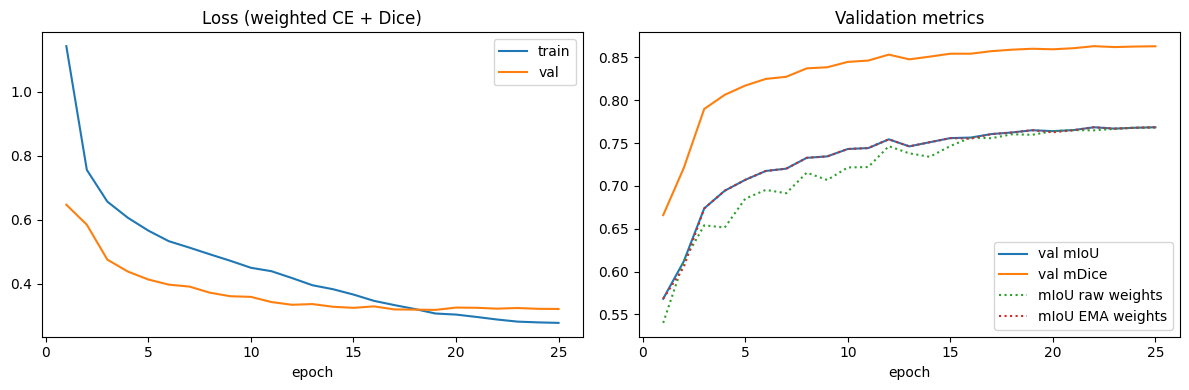

In [10]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set(title="Loss (weighted CE + Dice)", xlabel="epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_mIoU, label="val mIoU"); ax[1].plot(h.epoch, h.val_mDice, label="val mDice")
if "val_mIoU_ema" in h and h.val_mIoU_ema.notna().any():
    ax[1].plot(h.epoch, h.val_mIoU_raw, ls=":", label="mIoU raw weights"); ax[1].plot(h.epoch, h.val_mIoU_ema, ls=":", label="mIoU EMA weights")
ax[1].set(title="Validation metrics", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "curves.png", dpi=150); plt.show()

## 4. Test-set evaluation
Loads the **best** checkpoint (by validation mIoU) and evaluates once on the untouched test split.

best checkpoint: epoch 22, val mIoU 0.7685 (ema weights)


eval:   0%|          | 0/63 [00:00<?, ?it/s]

eval:   0%|          | 0/13 [00:00<?, ?it/s]

eval:   0%|          | 0/13 [00:00<?, ?it/s]

split               mIoU  mIoU(present)   mDice  pixAcc
val               0.7685         0.7685  0.8631  0.9816
test (no TTA)     0.6135         0.6748  0.7068  0.9745   (no GT pixels: ['scarf'])
test (flip TTA)   0.6150         0.6765  0.7078  0.9743   (no GT pixels: ['scarf'])


,class,val_IoU,test_IoU,test_IoU_TTA,test_Dice,train_pixel_share_%,test_GT_share_%
0,background,0.9904,0.9854,0.9855,0.9927,76.33,72.911
1,body,0.8610,0.9402,0.9420,0.9702,7.32,7.177
2,hat,0.7554,0.5202,0.4936,0.6610,0.18,0.023
3,upper-clothes,0.8267,0.8933,0.8909,0.9423,6.08,13.093
4,skirt,0.8083,0.6043,0.6135,0.7605,1.92,0.726
5,pants,0.8619,0.8699,0.8683,0.9295,2.86,5.563
6,dress,0.7513,0.2698,0.2557,0.4072,2.83,0.347
7,belt,0.5453,0.4911,0.5206,0.6847,0.10,0.013
8,shoes,0.7446,0.8324,0.8380,0.9119,1.00,0.128
9,bag,0.7672,0.3418,0.3566,0.5257,1.18,0.020


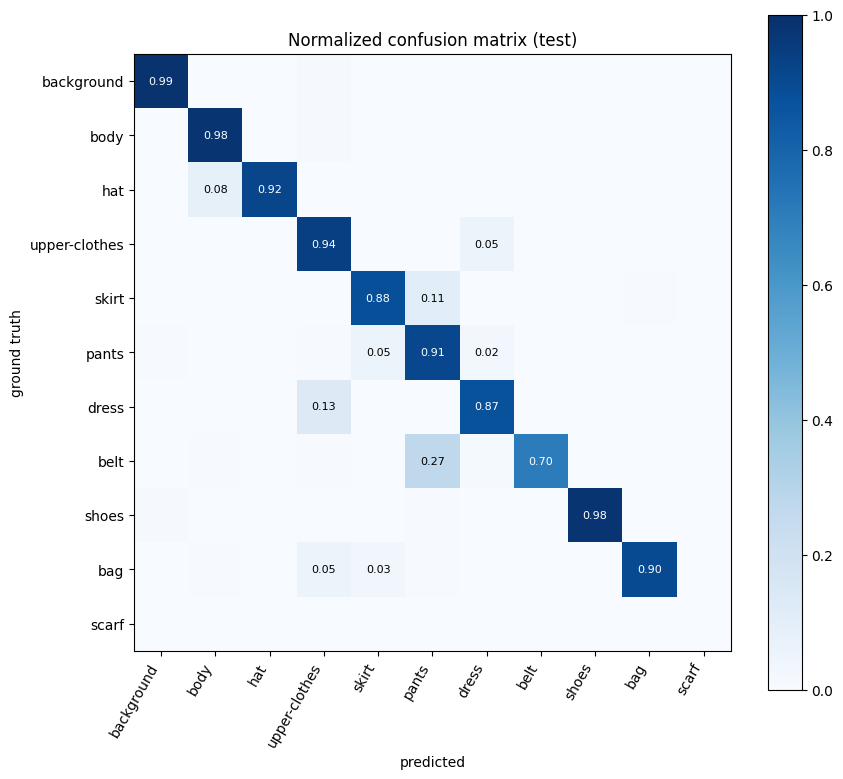

In [11]:
ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
print(f"best checkpoint: epoch {ck['epoch']}, val mIoU {ck['val_mIoU']:.4f}" + (f" ({ck['weights']} weights)" if "weights" in ck else ""))


def miou_present(conf, m):
    """mIoU over the classes that actually occur in the ground truth (a class with no GT pixels but a few false positives
    would otherwise count as IoU 0). Returns (value, list of classes absent from the ground truth)."""
    gt = conf.sum(1).cpu().numpy()
    keep = gt > 0
    return float(np.nanmean(np.array(m["iou"])[keep])), [n for n, k in zip(CLASS_NAMES, keep) if not k]


val_m, val_conf = evaluate(model, val_dl, criterion)
test_m0, test_conf0 = evaluate(model, test_dl, criterion)                         # no TTA
if CFG["tta_flip"]:
    test_m, test_conf = evaluate(model, test_dl, criterion, tta=True)             # flip TTA = the headline number
else:
    test_m, test_conf = test_m0, test_conf0

rows = [("val", val_m, val_conf), ("test (no TTA)", test_m0, test_conf0)]
if CFG["tta_flip"]:
    rows.append(("test (flip TTA)", test_m, test_conf))
print(f"{'split':16s} {'mIoU':>7s} {'mIoU(present)':>14s} {'mDice':>7s} {'pixAcc':>7s}")
for name, m, c in rows:
    mp, absent = miou_present(c, m)
    print(f"{name:16s} {m['mIoU']:7.4f} {mp:14.4f} {m['mDice']:7.4f} {m['pixel_acc']:7.4f}" + (f"   (no GT pixels: {absent})" if absent else ""))

per_class = pd.DataFrame({"class": CLASS_NAMES,
                          "val_IoU": np.round(val_m["iou"], 4),
                          "test_IoU": np.round(test_m0["iou"], 4)})
if CFG["tta_flip"]:
    per_class["test_IoU_TTA"] = np.round(test_m["iou"], 4)
per_class["test_Dice"] = np.round(test_m["dice"], 4)
per_class["train_pixel_share_%"] = (FREQ * 100).round(2)
per_class["test_GT_share_%"] = (test_conf.sum(1).double() / test_conf.sum().double() * 100).cpu().numpy().round(3)
display(per_class)
per_class.to_csv(OUT / "per_class_val_test.csv", index=False)
mp_val, _ = miou_present(val_conf, val_m); mp_test, absent_test = miou_present(test_conf, test_m)
json.dump({**{k: test_m[k] for k in ["mIoU", "mDice", "pixel_acc", "loss"]}, "mIoU_present_classes": mp_test,
           "classes_without_gt": absent_test, "val_mIoU": val_m["mIoU"], "val_mIoU_present_classes": mp_val,
           "test_mIoU_no_tta": test_m0["mIoU"], "tta_flip": bool(CFG["tta_flip"]),
           "class_names": CLASS_NAMES, "iou": test_m["iou"], "dice": test_m["dice"]},
          open(OUT / "test_metrics.json", "w"), indent=2)

# normalized confusion matrix (rows = ground truth)
cm = test_conf.double().cpu().numpy(); cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j] > 0.02:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
ax.set(xlabel="predicted", ylabel="ground truth", title="Normalized confusion matrix (test)")
plt.colorbar(im); plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=150); plt.show()

## 5. Failure analysis (Task 3: strengths, drawbacks, limitations)
Per-image score on the test set (mean IoU over classes present in the ground truth or the prediction), then the **best** and **worst** cases. Use these panels in the report.

per-image:   0%|          | 0/13 [00:00<?, ?it/s]

per-image mIoU: mean 0.831 | median 0.935 | 10th pct 0.586 | min 0.272


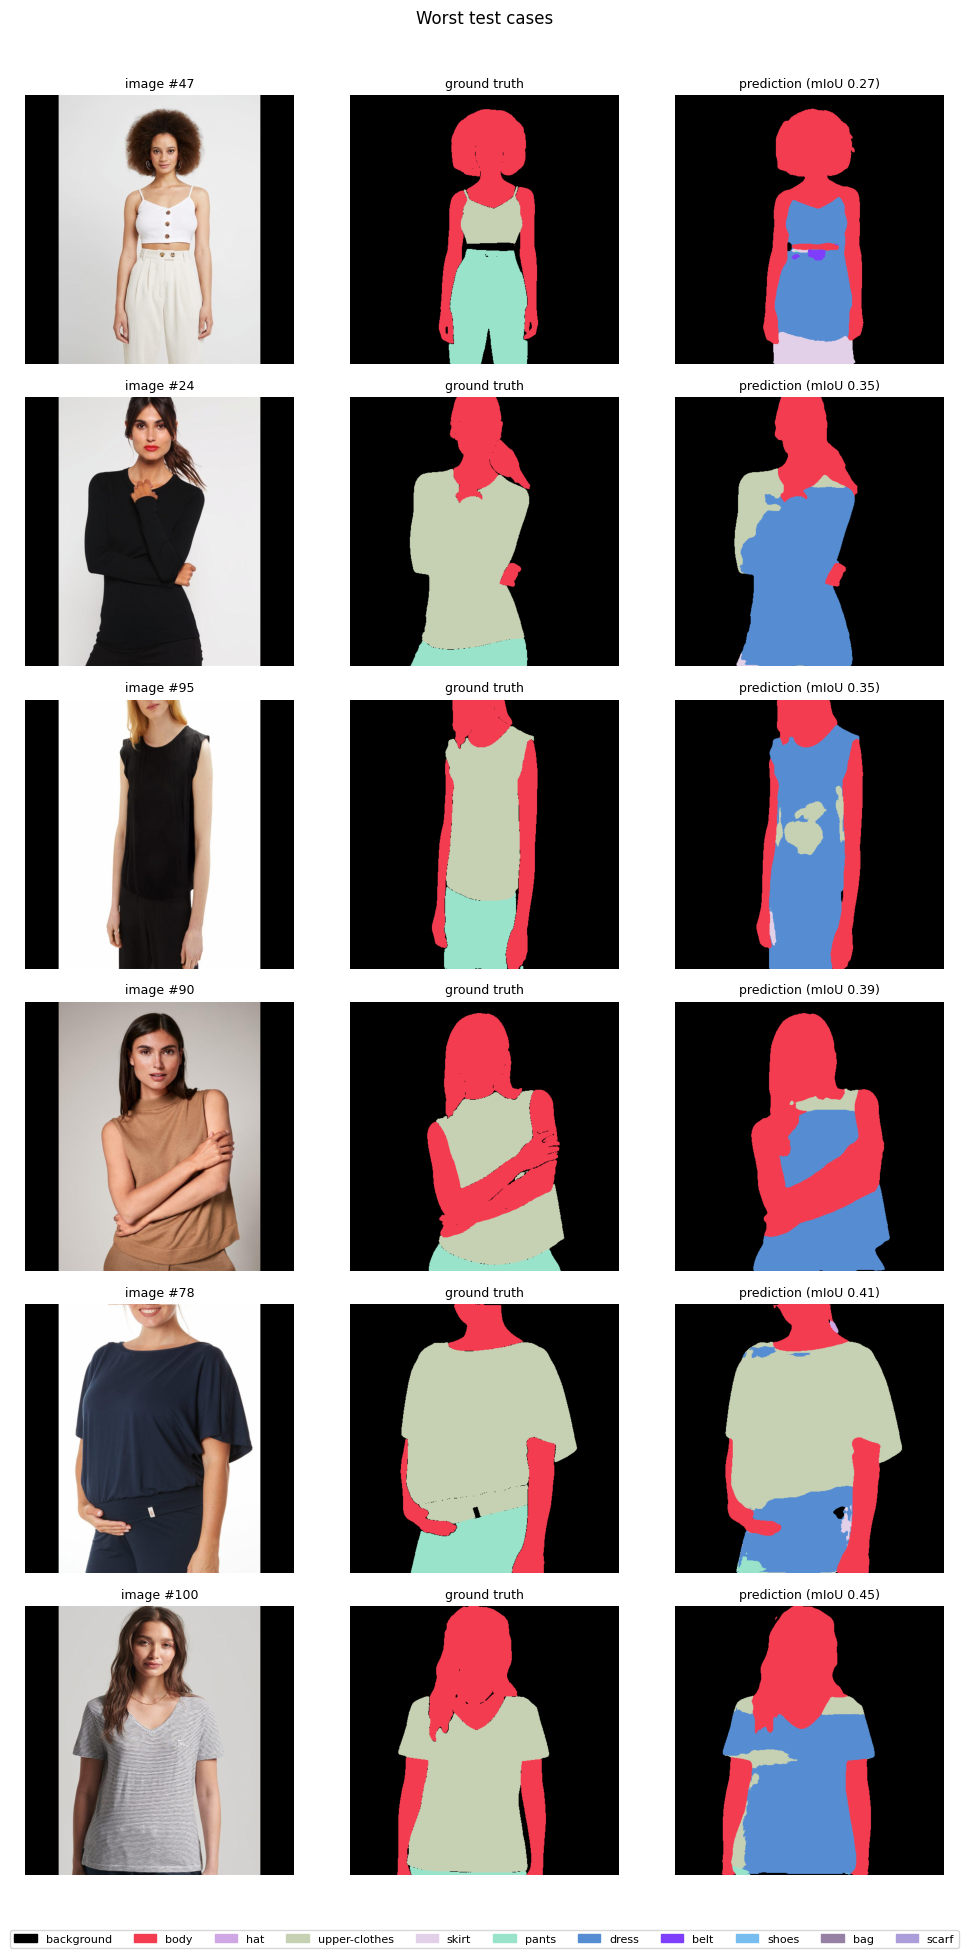

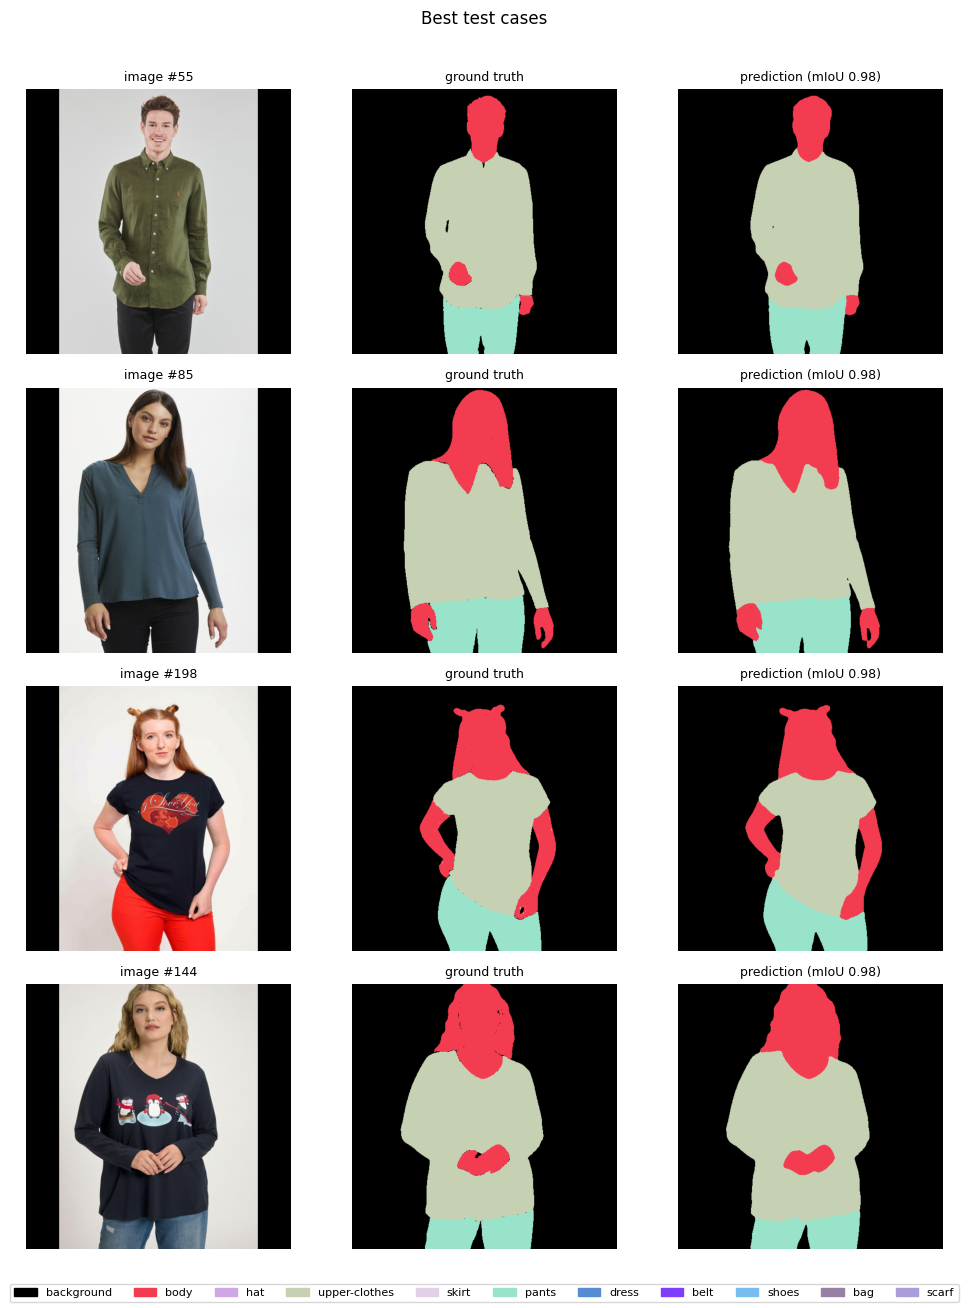

In [12]:
@torch.no_grad()
def per_image_scores(model, ds, n=600, bs=16):
    model.eval()
    n = min(n, len(ds)); scores = []
    dl = DataLoader(torch.utils.data.Subset(ds, range(n)), bs, shuffle=False, num_workers=2)
    for x, y in tqdm(dl, desc="per-image"):
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", enabled=USE_AMP):
            pred = predict_logits(model, x, CFG["tta_flip"]).argmax(1)
        for p, t in zip(pred, y):
            c = confusion(p, t, NUM_CLASSES).double().cpu().numpy()
            tp = np.diag(c); den = c.sum(0) + c.sum(1) - tp
            scores.append(float(np.nanmean(np.where(den > 0, tp / np.maximum(den, 1), np.nan))))
    return np.array(scores)


@torch.no_grad()
def show_cases(model, ds, idxs, scores, title, fname):
    model.eval()
    fig, axes = plt.subplots(len(idxs), 3, figsize=(10, 3.3 * len(idxs)))
    for r, i in enumerate(idxs):
        x, y = ds[int(i)]
        with torch.autocast("cuda", enabled=USE_AMP):
            p = predict_logits(model, x.unsqueeze(0).to(device), CFG["tta_flip"]).argmax(1)[0].cpu().numpy()
        for c, (im, t) in enumerate([(denorm(x), f"image #{i}"), (PALETTE[y.numpy()], "ground truth"),
                                     (PALETTE[p], f"prediction (mIoU {scores[i]:.2f})")]):
            axes[r, c].imshow(im); axes[r, c].set_title(t, fontsize=9); axes[r, c].axis("off")
    fig.legend(handles=[Patch(color=PALETTE[i] / 255, label=n) for i, n in enumerate(CLASS_NAMES)],
               loc="lower center", ncol=min(NUM_CLASSES, 11), fontsize=8)
    plt.suptitle(title); plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.savefig(OUT / fname, dpi=120, bbox_inches="tight"); plt.show()


scores = per_image_scores(model, test_ds)
print(f"per-image mIoU: mean {scores.mean():.3f} | median {np.median(scores):.3f} | "
      f"10th pct {np.percentile(scores, 10):.3f} | min {scores.min():.3f}")
order = np.argsort(scores)
show_cases(model, test_ds, order[:6], scores, "Worst test cases", "worst_cases.png")
show_cases(model, test_ds, order[-4:][::-1], scores, "Best test cases", "best_cases.png")

## 6. Inference pipeline on personal photos

Upload your photos as a Kaggle dataset (**Add Input -> Upload**) and set `PHOTO_DIR` below, e.g. `"/kaggle/input/my-photos"`.
If it is `None`, a few test images are used instead.

The photo is letterboxed to the model size, the padding is removed from the prediction, and the mask is resized back to the original photo resolution. Outputs: color mask, overlay and a transparent **clothes-only cutout** (the virtual-fitting use case).

تم العثور على 1 صورة.
My image.jpeg


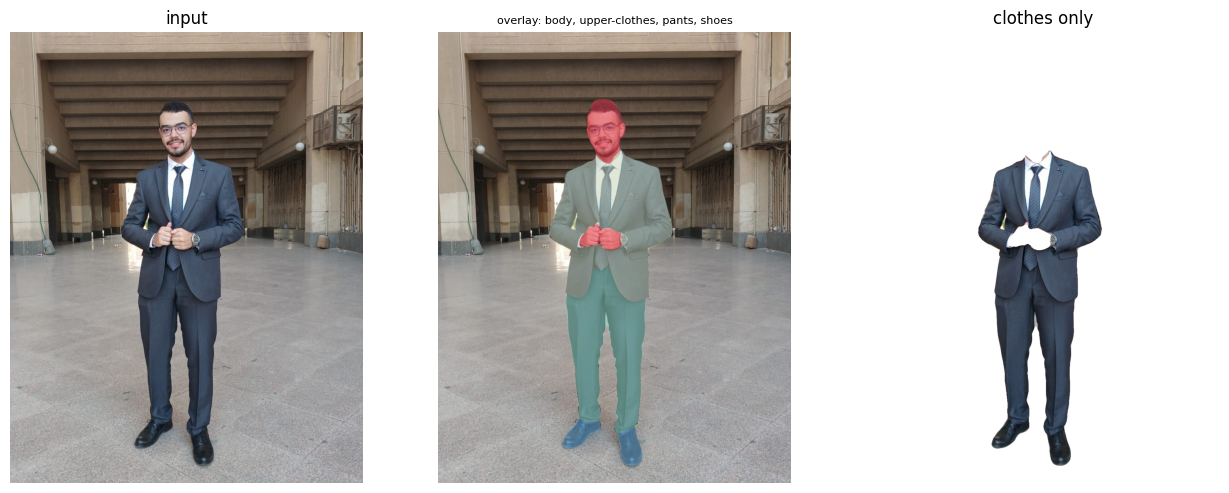

In [22]:
# from pathlib import Path
# import cv2
# import matplotlib.pyplot as plt
# import numpy as np
# from PIL import Image
# import torch
# import torch.nn.functional as F

PHOTO_DIR = "/kaggle/input/datasets/mahmoudosamahassan/my-photo/My image.jpeg"
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def preprocess(img_rgb, size):
    h, w = img_rgb.shape[:2]
    s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    resized = cv2.resize(img_rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas = np.zeros((size, size, 3), dtype=np.uint8)
    canvas[top : top + nh, left : left + nw] = resized
    x = (canvas.astype(np.float32) / 255.0 - np.array(MEAN, np.float32)) / np.array(
        STD, np.float32
    )
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0), (
        top,
        left,
        nh,
        nw,
    )


@torch.no_grad()
def predict_image(model, img_rgb, size=SIZE):
    model.eval()
    h, w = img_rgb.shape[:2]
    x, (top, left, nh, nw) = preprocess(img_rgb, size)
    with torch.autocast("cuda", enabled=USE_AMP):
        logits = predict_logits(model, x.to(device), CFG["tta_flip"])
    logits = logits[:, :, top : top + nh, left : left + nw].float()
    logits = F.interpolate(
        logits, size=(h, w), mode="bilinear", align_corners=False
    )
    return logits.argmax(1)[0].cpu().numpy().astype(np.uint8)


def segment_photo(path_or_array, save_as=None, alpha=0.5, show=True):
    if isinstance(path_or_array, (str, Path)):
        img_bgr = cv2.imread(str(path_or_array))
        if img_bgr is None:
            # استخدام PIL كبديل آمن لقراءة المسارات التي تحتوي على مسافات
            rgb = np.array(Image.open(path_or_array).convert("RGB"))
        else:
            rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    else:
        rgb = path_or_array

    mask = predict_image(model, rgb)
    color = PALETTE[mask]
    overlay = np.where(
        (mask > 0)[..., None],
        (rgb * (1 - alpha) + color * alpha).astype(np.uint8),
        rgb,
    )
    clothes = np.isin(mask, CLOTHES_IDS)
    cutout = np.dstack([rgb, (clothes * 255).astype(np.uint8)])
    found = [CLASS_NAMES[i] for i in np.unique(mask) if i != 0]

    if save_as:
        out_dir = OUT / "samples"
        out_dir.mkdir(exist_ok=True, parents=True)
        cv2.imwrite(
            str(out_dir / f"{save_as}_mask.png"),
            cv2.cvtColor(color, cv2.COLOR_RGB2BGR),
        )
        cv2.imwrite(
            str(out_dir / f"{save_as}_overlay.png"),
            cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR),
        )
        cv2.imwrite(
            str(out_dir / f"{save_as}_clothes.png"),
            cv2.cvtColor(cutout, cv2.COLOR_RGBA2BGRA),
        )

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(13, 5))
        ax[0].imshow(rgb)
        ax[0].set_title("input")
        ax[1].imshow(overlay)
        ax[1].set_title(
            "overlay: " + (", ".join(found) if found else "none"), fontsize=8
        )
        ax[2].imshow(np.where(clothes[..., None], rgb, 255).astype(np.uint8))
        ax[2].set_title("clothes only")
        for a in ax:
            a.axis("off")
        plt.tight_layout()
        plt.show()

    return mask


# --- تحديد الملفات والتعامل مع الملف المباشر أو المجلد ---
target_path = Path(PHOTO_DIR)

if target_path.is_file() and target_path.suffix.lower() in EXTS:
    files = [target_path]
elif target_path.is_dir():
    files = sorted(p for p in target_path.rglob("*") if p.suffix.lower() in EXTS)
else:
    print("المسار غير صالح أو غير موجود، جاري استخدام صور الـ test...")
    files = test_ds.images[:4]

print(f"تم العثور على {len(files)} صورة.")

for f in files:
    print(f.name)
    segment_photo(f, save_as=Path(f).stem)

In [14]:
# Model facts for the report: size and inference speed
model.eval()
x = torch.randn(1, 3, SIZE, SIZE, device=device)
with torch.no_grad(), torch.autocast("cuda", enabled=USE_AMP):
    for _ in range(10): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(50): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
ms = (time.time() - t) / 50 * 1000
print(f"parameters: {n_params:.1f}M | input {SIZE}x{SIZE} | {ms:.1f} ms/image on {device} "
      f"({1000 / ms:.0f} FPS, batch 1, AMP={USE_AMP})")

parameters: 24.4M | input 512x512 | 9.2 ms/image on cuda (109 FPS, batch 1, AMP=True)


## 7. Export
Everything needed for the later scripts version is in `/kaggle/working/outputs`:
`best.pt` (weights + config + class names), `history.csv`, `curves.png`, `test_metrics.json`, `test_per_class.csv`, `confusion_matrix.png`, `worst_cases.png`, `best_cases.png`, `samples/`.

**Remember: Save Version -> Save & Run All (Commit)** to keep these files, then download `best.pt` from the notebook's *Output* tab.

In [15]:
total = 0
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        mb = p.stat().st_size / 1e6; total += mb
        print(f"{str(p.relative_to(OUT)):40s} {mb:8.1f} MB")
print(f"{'total':40s} {total:8.1f} MB")
# last.pt (optimizer state) is only needed for resuming; delete it if you want a smaller output:
# (OUT / "last.pt").unlink()

augmentation_samples.png                      0.7 MB
best.pt                                      97.9 MB
best_cases.png                                0.4 MB
class_frequencies.csv                         0.0 MB
confusion_matrix.png                          0.1 MB
curves.png                                    0.1 MB
history.csv                                   0.0 MB
last.pt                                     391.4 MB
per_class_val_test.csv                        0.0 MB
samples/00000_clothes.png                     0.5 MB
samples/00000_mask.png                        0.0 MB
samples/00000_overlay.png                     0.3 MB
samples/00001_clothes.png                     0.6 MB
samples/00001_mask.png                        0.0 MB
samples/00001_overlay.png                     0.5 MB
samples/00002_clothes.png                     0.5 MB
samples/00002_mask.png                        0.0 MB
samples/00002_overlay.png                     0.4 MB
samples/00003_clothes.png                     